In [1]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 22.6 MB/s eta 0:00:00


In [8]:
import os
import cv2
import easyocr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

import joblib

In [9]:
import os
import zipfile

ZIP_PATH = "/content/HumanCognitive.zip"
DATASET_PATH = "/content/HumanCognitive"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_PATH)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(DATASET_PATH):
    image_count = sum(
        1 for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
    )

    if image_count > 0:
        print(root, "->", image_count, "images")

Dataset extracted successfully!
/content/HumanCognitive/HumanCognitive -> 105 images


In [10]:
import os
import cv2
import easyocr
import numpy as np
import pandas as pd

# Dataset folder
DATASET_PATH = "/content/HumanCognitive"

# Initialize OCR
reader = easyocr.Reader(['en'], gpu=False)

def extract_features(image_path):
    image = cv2.imread(image_path)

    if image is None:
        print("Skipping unreadable image:", image_path)
        return None

    height, width = image.shape[:2]
    image_area = height * width

    # OCR features
    results = reader.readtext(image_path)

    word_count = 0
    text_block_count = len(results)
    total_text_area = 0

    for box, text, confidence in results:
        word_count += len(text.split())

        x_coordinates = [point[0] for point in box]
        y_coordinates = [point[1] for point in box]

        box_width = max(x_coordinates) - min(x_coordinates)
        box_height = max(y_coordinates) - min(y_coordinates)

        total_text_area += box_width * box_height

    text_density = min(total_text_area / image_area, 1.0)
    text_block_density = text_block_count / (image_area / 1_000_000)

    # OpenCV visual features
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray)
    contrast = np.std(gray)

    edges = cv2.Canny(gray, 100, 200)
    edge_density = np.mean(edges > 0)

    # Approximate whitespace ratio
    small_gray = cv2.resize(gray, (100, 100))
    empty_patches = 0

    for y in range(0, 100, 10):
        for x in range(0, 100, 10):
            patch = small_gray[y:y+10, x:x+10]

            if np.std(patch) < 15:
                empty_patches += 1

    whitespace_ratio = empty_patches / 100

    return {
        "image_name": os.path.relpath(image_path, DATASET_PATH),
        "word_count": word_count,
        "text_block_count": text_block_count,
        "text_density": text_density,
        "text_block_density": text_block_density,
        "brightness": brightness,
        "contrast": contrast,
        "edge_density": edge_density,
        "whitespace_ratio": whitespace_ratio
    }


# Find all PNG images
image_paths = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(".png"):
            image_paths.append(os.path.join(root, file))

image_paths.sort()

print("Total images found:", len(image_paths))

# Extract features
rows = []

for i, image_path in enumerate(image_paths, start=1):
    features = extract_features(image_path)

    if features is not None:
        rows.append(features)

    if i % 10 == 0:
        print(f"Processed {i}/{len(image_paths)} images")

# Create a single dataframe
df = pd.DataFrame(rows)

# Save the CSV
CSV_PATH = "/content/website_complexity_dataset.csv"
df.to_csv(CSV_PATH, index=False)

print("\nFeature extraction completed!")
print("Rows:", len(df))
print("\nDataset preview:")
display(df.head())

print("\nCSV saved to:", CSV_PATH)

Total images found: 105


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argume

Processed 10/105 images


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argume

Processed 20/105 images


...

Processed 100/105 images


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argume


Feature extraction completed!
Rows: 105

Dataset preview:


,image_name,word_count,text_block_count,text_density,text_block_density,brightness,contrast,edge_density,whitespace_ratio
0,HumanCognitive/1.png,47,20,0.052576,11.968021,192.886720,64.515640,0.027260,0.14
1,HumanCognitive/Gemini_Generated_Image_1p167x1p...,90,46,0.107803,43.528949,219.738234,63.022786,0.028242,0.37
2,HumanCognitive/Gemini_Generated_Image_1p167x1p...,135,71,0.090486,67.185986,186.797588,71.481121,0.054805,0.10
3,HumanCognitive/Gemini_Generated_Image_1p167x1p...,125,71,0.132995,67.185986,175.335406,94.638308,0.068868,0.09
4,HumanCognitive/Gemini_Generated_Image_1p167x1p...,87,41,0.140542,38.797541,206.836052,82.750000,0.044135,0.22



CSV saved to: /content/website_complexity_dataset.csv


In [11]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (105, 9)

Column names:
['image_name', 'word_count', 'text_block_count', 'text_density', 'text_block_density', 'brightness', 'contrast', 'edge_density', 'whitespace_ratio']

First 5 rows:


,image_name,word_count,text_block_count,text_density,text_block_density,brightness,contrast,edge_density,whitespace_ratio
0,HumanCognitive/1.png,47,20,0.052576,11.968021,192.886720,64.515640,0.027260,0.14
1,HumanCognitive/Gemini_Generated_Image_1p167x1p...,90,46,0.107803,43.528949,219.738234,63.022786,0.028242,0.37
2,HumanCognitive/Gemini_Generated_Image_1p167x1p...,135,71,0.090486,67.185986,186.797588,71.481121,0.054805,0.10
3,HumanCognitive/Gemini_Generated_Image_1p167x1p...,125,71,0.132995,67.185986,175.335406,94.638308,0.068868,0.09
4,HumanCognitive/Gemini_Generated_Image_1p167x1p...,87,41,0.140542,38.797541,206.836052,82.750000,0.044135,0.22



Missing values:
image_name            0
word_count            0
text_block_count      0
text_density          0
text_block_density    0
brightness            0
contrast              0
edge_density          0
whitespace_ratio      0
dtype: int64


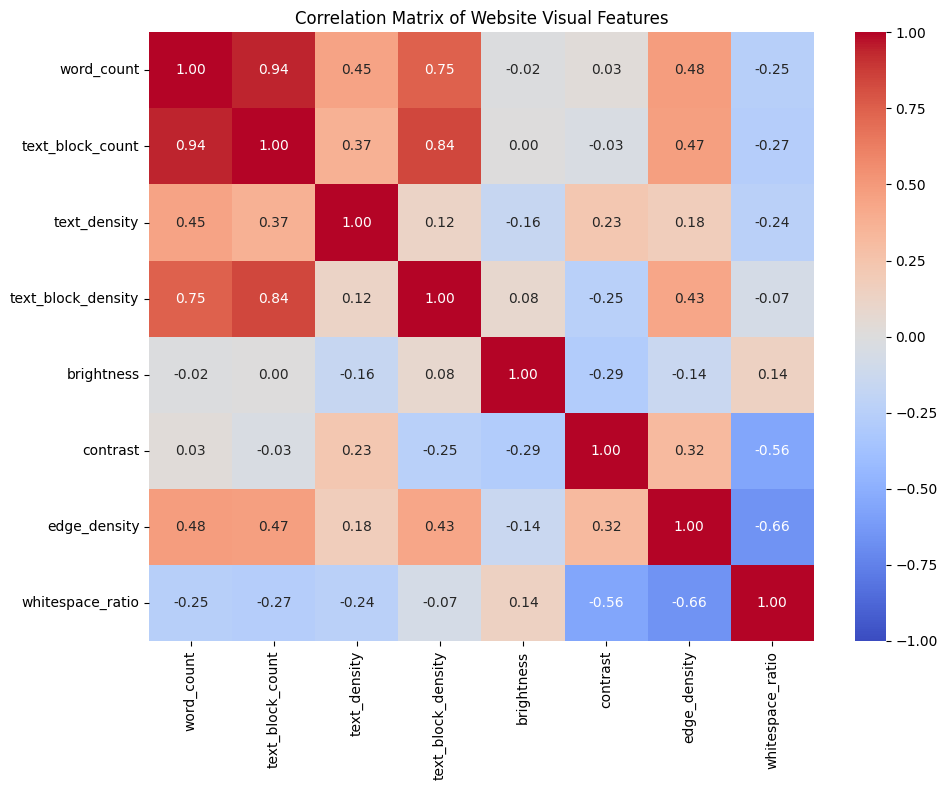

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_columns = [
    "word_count",
    "text_block_count",
    "text_density",
    "text_block_density",
    "brightness",
    "contrast",
    "edge_density",
    "whitespace_ratio"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix of Website Visual Features")
plt.tight_layout()
plt.show()

In [14]:
def normalize(series):
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return pd.Series(0.0, index=series.index)

    return (series - minimum) / (maximum - minimum)


# Normalize selected features to a range of 0 to 1
text_score = normalize(df["text_density"])
edge_score = normalize(df["edge_density"])
block_score = normalize(df["text_block_density"])

# Keep whitespace ratio within the range 0 to 1
whitespace_score = df["whitespace_ratio"].clip(0, 1)


# Calculate the heuristic complexity score
df["complexity_score"] = (
    100 * (
        0.35 * text_score
        + 0.25 * edge_score
        + 0.20 * block_score
        + 0.20 * (1 - whitespace_score)
    )
).clip(0, 100).round(2)


# Save the updated dataset
df.to_csv("/content/website_complexity_dataset.csv", index=False)

display(
    df[["image_name", "complexity_score"]].head(10)
)

,image_name,complexity_score
0,HumanCognitive/1.png,25.97
1,HumanCognitive/Gemini_Generated_Image_1p167x1p...,31.37
2,HumanCognitive/Gemini_Generated_Image_1p167x1p...,43.20
3,HumanCognitive/Gemini_Generated_Image_1p167x1p...,52.14
4,HumanCognitive/Gemini_Generated_Image_1p167x1p...,41.91
5,HumanCognitive/Gemini_Generated_Image_g07u5wg0...,43.66
6,HumanCognitive/Gemini_Generated_Image_ju8xj9ju...,41.81
7,HumanCognitive/Gemini_Generated_Image_ju8xj9ju...,35.36
8,HumanCognitive/Gemini_Generated_Image_ju8xj9ju...,28.76
9,HumanCognitive/Gemini_Generated_Image_rjr9ogrj...,30.64


In [21]:
!pip install -q -U google-genai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.0/268.0 kB 20.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.61.0 which is incompatible.


In [24]:
from google.colab import userdata
from google import genai

api_key = userdata.get("GEMINI_API_KEY")

client = genai.Client(api_key=api_key)

print("Gemini client initialized successfully!")

Gemini client initialized successfully!


In [25]:
import os

image_folder = "/content/HumanCognitive"

print("Folder exists:", os.path.exists(image_folder))

if os.path.exists(image_folder):
    print("First few files:", os.listdir(image_folder)[:10])

Folder exists: True
First few files: ['HumanCognitive']


In [26]:
import os

image_extensions = (".png", ".jpg", ".jpeg", ".webp")

image_paths = []

for root, dirs, files in os.walk(image_folder):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, file))

image_paths.sort()

print("Total screenshots found:", len(image_paths))

if len(image_paths) > 0:
    print("Test screenshot:", image_paths[0])
else:
    print("No screenshots found. Check the folder path.")

Total screenshots found: 105
Test screenshot: /content/HumanCognitive/HumanCognitive/1.png


In [27]:
MODEL_NAME="gemini-3.8-flash"

In [29]:
import time
from google.genai.errors import ServerError

response = None

for attempt in range(4):
    try:
        print(f"Attempt {attempt + 1}/4...")

        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=[prompt, test_image]
        )

        print("Success!")
        print(response.text)
        break

    except ServerError as e:
        print("Gemini server error:", e)

        if attempt < 3:
            wait_time = 5 * (attempt + 1)
            print(f"Waiting {wait_time} seconds before retrying...")
            time.sleep(wait_time)
        else:
            print("All attempts failed. Try another available model.")

Attempt 1/4...
Success!
```json
{
  "visual_density": 2,
  "text_complexity": 1,
  "layout_complexity": 2,
  "visual_clutter": 1,
  "visual_hierarchy": 5,
  "whitespace": 4,
  "overall_complexity": 20,
  "reason": "The page features a clean, highly structured layout with minimal text, generous spacing, and a strong visual hierarchy centered around the hero promotional banner."
}
```


In [30]:
import time
import json
import re
import pandas as pd
from PIL import Image as PILImage
from google.colab import userdata
from google import genai
from google.genai.errors import ServerError

# Model that worked in your single-image test
MODEL_NAME = "gemini-3.8-flash"

# Get the API key from Colab Secrets
api_key = userdata.get("GEMINI_API_KEY")

if not api_key:
    raise ValueError(
        "GEMINI_API_KEY not found. Add it in Colab Secrets."
    )

client = genai.Client(api_key=api_key)

prompt = """
You are evaluating website screenshots for an academic machine learning project.

Analyze only the visible website interface.
Do not claim to measure a person's actual cognitive load.

Rate these properties using integers from 1 to 5:

1. visual_density:
   1 = very sparse, 5 = extremely dense

2. text_complexity:
   1 = very little or simple text, 5 = extensive or complex text

3. layout_complexity:
   1 = simple layout, 5 = highly complex layout

4. visual_clutter:
   1 = very uncluttered, 5 = extremely cluttered

5. visual_hierarchy:
   1 = unclear hierarchy, 5 = very clear hierarchy

6. whitespace:
   1 = very little whitespace, 5 = abundant whitespace

Assign an overall_complexity score from 0 to 100.

Consider visual density, text complexity, layout complexity, and
visual clutter when assigning the overall score. A clear visual
hierarchy and effective whitespace may reduce perceived complexity.

Use your judgment consistently. Do not assign the score solely
based on the number of words.

Return ONLY a valid JSON object in this format:

{
  "visual_density": 2,
  "text_complexity": 1,
  "layout_complexity": 2,
  "visual_clutter": 1,
  "visual_hierarchy": 5,
  "whitespace": 4,
  "overall_complexity": 20,
  "reason": "Brief explanation of the score"
}
"""

print("Gemini client initialized successfully.")
print("Model:", MODEL_NAME)

Gemini client initialized successfully.
Model: gemini-3.8-flash


In [31]:
import os
import json
import re
import time
import pandas as pd
from PIL import Image as PILImage

progress_file = "/content/gemini_scores_progress.csv"

score_columns = [
    "visual_density",
    "text_complexity",
    "layout_complexity",
    "visual_clutter",
    "visual_hierarchy",
    "whitespace",
    "overall_complexity",
    "reason"
]

# Convert image paths to the relative filenames used in df
def get_relative_image_name(image_path):
    return os.path.relpath(
        image_path, image_folder
    ).replace("\\", "/")

# Parse the JSON response
def parse_gemini_json(response_text):
    text = response_text.strip()

    # Remove optional Markdown code fences
    text = re.sub(r"^```(?:json)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    return json.loads(text)


# Load previously saved scores if available
if os.path.exists(progress_file):

    scores_df = pd.read_csv(progress_file)

    # Keep only rows with complete, valid scores
    scores_df = scores_df.dropna(
        subset=score_columns
    ).copy()

    scores_df["image_name"] = (
        scores_df["image_name"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    # If a filename appears more than once, keep the latest row
    scores_df = scores_df.drop_duplicates(
        subset=["image_name"],
        keep="last"
    )

    print("Loaded previous progress:", len(scores_df), "screenshots")

else:

    scores_df = pd.DataFrame(
        columns=["image_name"] + score_columns
    )

    print("Starting a new scoring run.")


completed_images = set(scores_df["image_name"].astype(str))

for index, image_path in enumerate(image_paths, start=1):

    image_name = get_relative_image_name(image_path)

    # Skip screenshots already scored successfully
    if image_name in completed_images:
        continue

    print(f"\nProcessing {index}/{len(image_paths)}: {image_name}")

    result = None

    for attempt in range(4):

        try:

            with PILImage.open(image_path) as img:
                screenshot = img.convert("RGB")

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=[prompt, screenshot]
            )

            result = parse_gemini_json(response.text)

            # Check that all required fields exist
            missing_fields = [
                col for col in score_columns
                if col not in result
            ]

            if missing_fields:
                raise ValueError(
                    f"Missing fields: {missing_fields}"
                )

            # Convert ratings and score to integers
            for col in score_columns[:-1]:
                result[col] = int(result[col])

            # Validate ratings
            for col in score_columns[:-1]:

                if col == "overall_complexity":
                    if not 0 <= result[col] <= 100:
                        raise ValueError(
                            "Overall complexity must be between 0 and 100."
                        )

                elif not 1 <= result[col] <= 5:
                    raise ValueError(
                        f"{col} must be between 1 and 5."
                    )

            result["reason"] = str(result["reason"])

            break

        except Exception as e:

            print(f"Attempt {attempt + 1}/4 failed: {e}")

            result = None

            if attempt < 3:
                wait_seconds = 5 * (attempt + 1)
                print(f"Retrying in {wait_seconds} seconds...")
                time.sleep(wait_seconds)

            else:
                print("Skipping this screenshot for now.")

    if result is not None:

        new_row = {
            "image_name": image_name,
            **{
                col: result[col]
                for col in score_columns
            }
        }

        scores_df = pd.concat(
            [scores_df, pd.DataFrame([new_row])],
            ignore_index=True
        )

        completed_images.add(image_name)

        # Save progress immediately
        scores_df.to_csv(progress_file, index=False)

        print("Overall complexity:", result["overall_complexity"])
        print("Reason:", result["reason"])

        # Pause between requests
        time.sleep(2)


print("\nScoring finished.")
print("Successfully scored:", len(scores_df))
print("Total screenshots:", len(image_paths))
print("Unscored screenshots:", len(image_paths) - len(scores_df))
print("Progress saved to:", progress_file)

Starting a new scoring run.

Processing 1/105: HumanCognitive/1.png
Attempt 1/4 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying in 5 seconds...
Attempt 2/4 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Retrying in 10 seconds...
Overall complexity: 20
Reason: The page exhibits a clean, conventional e-commerce layout dominated by a focused promotional hero banner. Text is minimal and concise, spacing is generous, and visual hierarchy is exceptionally clear.

Processing 2/105: HumanCognitive/Gemini_Generated_Image_1p167x1p167x1p16 (1).png
Overall complexity: 18
Reason: The page features a clean, minimalist design with a prominent hero section, abundant whitespace, clear typ

In [32]:
import pandas as pd
import os

progress_file = "/content/gemini_scores_progress.csv"

scores_df = pd.read_csv(progress_file)

print("Successfully saved score rows:", len(scores_df))
print("Unique screenshots scored:", scores_df["image_name"].nunique())
print("Total screenshots:", 105)
print("Remaining:", 105 - scores_df["image_name"].nunique())

print("\nLast 5 saved results:")
display(scores_df.tail())

Successfully saved score rows: 14
Unique screenshots scored: 14
Total screenshots: 105
Remaining: 91

Last 5 saved results:


,image_name,visual_density,text_complexity,layout_complexity,visual_clutter,visual_hierarchy,whitespace,overall_complexity,reason
9,HumanCognitive/Gemini_Generated_Image_rjr9ogrj...,2,1,2,1,5,5,16,"The interface features a minimal, spacious dar..."
10,HumanCognitive/Gemini_Generated_Image_rjr9ogrj...,3,2,3,2,4,3,38,The page uses a standard course catalog layout...
11,HumanCognitive/Gemini_Generated_Image_roni3xro...,3,2,2,2,4,4,26,"The page uses a clean, predictable card-based ..."
12,HumanCognitive/Gemini_Generated_Image_roni3xro...,5,3,4,3,4,2,68,The interface features a dense 5-column grid o...
13,HumanCognitive/Gemini_Generated_Image_roni3xro...,4,3,4,3,4,2,58,The interface features a complex three-column ...


In [35]:
feature_columns = [
    "word_count",
    "text_block_count",
    "text_density",
    "text_block_density",
    "brightness",
    "contrast",
    "edge_density",
    "whitespace_ratio"
]

X = df[feature_columns]

y = df["complexity_score"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (105, 8)
Target data shape: (105,)


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 84
Testing samples: 21


In [41]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    random_state=42
)

# Train both model

rf_model.fit(X_train, y_train)

print("trained successfully!")

trained successfully!


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

r2 = r2_score(y_test, predictions)

print("-" * 30)
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

------------------------------
MAE:  3.09
RMSE: 4.62
R²:   0.8815


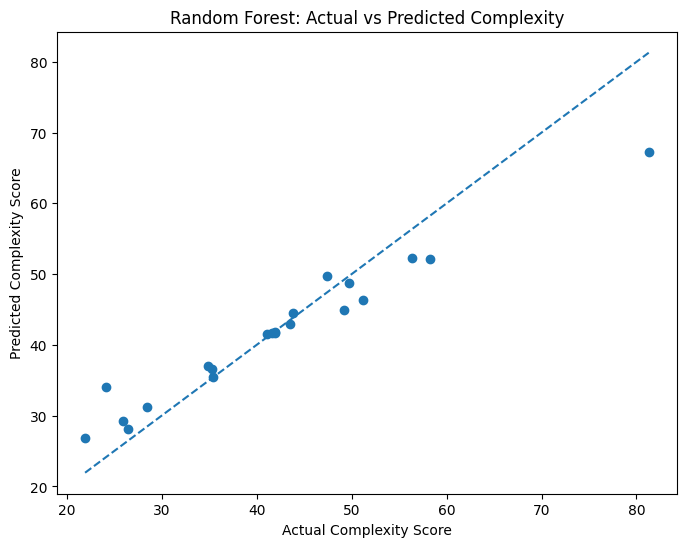

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Complexity Score")
plt.ylabel("Predicted Complexity Score")
plt.title("Random Forest: Actual vs Predicted Complexity")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

              Feature  Importance
6        edge_density    0.465256
2        text_density    0.285232
1    text_block_count    0.071136
7    whitespace_ratio    0.068151
0          word_count    0.055708
3  text_block_density    0.041163
5            contrast    0.008121
4          brightness    0.005233


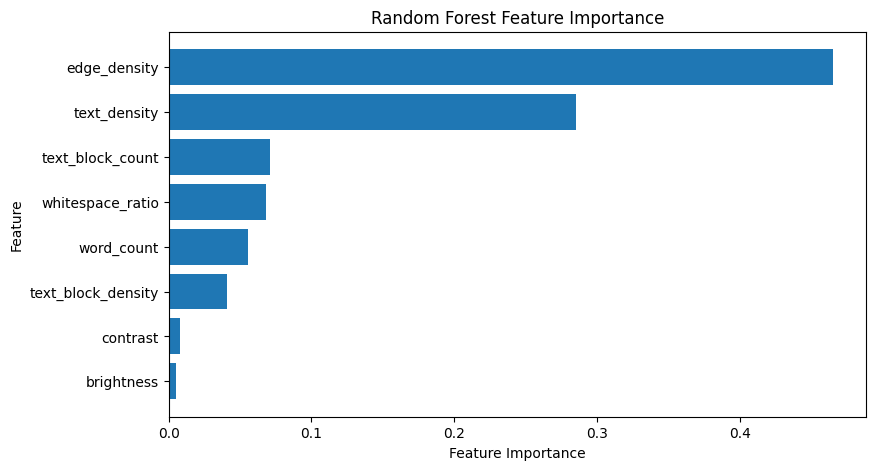

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [47]:
import joblib

joblib.dump(rf_model, "/content/random_forest_model.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [53]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded image:", image_path)

Saving Screenshot 2026-10-13 020905.png to Screenshot 2026-10-13 020905.png
Uploaded image: Screenshot 2026-10-13 020905.png


In [54]:
import cv2
import numpy as np
import pandas as pd
import easyocr
import os

# Initialize OCR reader
reader = easyocr.Reader(['en'], gpu=False)

# Read the uploaded screenshot
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Could not read the uploaded image.")

# Get image dimensions
height, width = image.shape[:2]
image_area = height * width

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# --------------------------------
# 1. Extract text using EasyOCR
# --------------------------------

ocr_results = reader.readtext(image)

word_count = sum(
    len(text.split())
    for _, text, confidence in ocr_results
)

text_block_count = len(ocr_results)

# --------------------------------
# 2. Calculate text density
# --------------------------------

total_text_area = 0

for bbox, text, confidence in ocr_results:
    xs = [point[0] for point in bbox]
    ys = [point[1] for point in bbox]

    box_width = max(xs) - min(xs)
    box_height = max(ys) - min(ys)

    total_text_area += box_width * box_height

text_density = total_text_area / image_area

# --------------------------------
# 3. Calculate text block density
# --------------------------------

text_block_density = text_block_count / (image_area / 1_000_000)

# --------------------------------
# 4. Calculate brightness
# --------------------------------

brightness = np.mean(gray)

# --------------------------------
# 5. Calculate contrast
# --------------------------------

contrast = np.std(gray)

# --------------------------------
# 6. Calculate edge density
# --------------------------------

edges = cv2.Canny(gray, 100, 200)

edge_density = np.count_nonzero(edges) / image_area

# --------------------------------
# 7. Calculate whitespace ratio
# --------------------------------

resized = cv2.resize(gray, (100, 100))

patch_size = 10
uniform_patches = 0
total_patches = 0

for y in range(0, 100, patch_size):
    for x in range(0, 100, patch_size):

        patch = resized[
            y:y + patch_size,
            x:x + patch_size
        ]

        if np.std(patch) < 15:
            uniform_patches += 1

        total_patches += 1

whitespace_ratio = uniform_patches / total_patches

# --------------------------------
# Display extracted features
# --------------------------------

feature_columns = [
    "word_count",
    "text_block_count",
    "text_density",
    "text_block_density",
    "brightness",
    "contrast",
    "edge_density",
    "whitespace_ratio"
]

new_features = pd.DataFrame([{
    "word_count": word_count,
    "text_block_count": text_block_count,
    "text_density": text_density,
    "text_block_density": text_block_density,
    "brightness": brightness,
    "contrast": contrast,
    "edge_density": edge_density,
    "whitespace_ratio": whitespace_ratio
}])

print("Extracted features:")
display(new_features)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Extracted features:


,word_count,text_block_count,text_density,text_block_density,brightness,contrast,edge_density,whitespace_ratio
0,145,117,0.29597,558.083627,205.255116,56.857618,0.208432,0.0


In [55]:
new_features = new_features[feature_columns]

# Predict complexity
prediction = rf_model.predict(new_features)[0]

# Keep the displayed result within the intended score range
prediction = np.clip(prediction, 0, 100)

print("=" * 40)
print("WEBSITE COMPLEXITY PREDICTION")
print("=" * 40)

print("Website:", os.path.basename(image_path))
print(f"Predicted Complexity Score: {prediction:.2f}/100")

if prediction < 30:
    print("Interpretation: Low predicted complexity")
elif prediction < 60:
    print("Interpretation: Moderate predicted complexity")
else:
    print("Interpretation: High predicted complexity")

print("=" * 40)

WEBSITE COMPLEXITY PREDICTION
Website: Screenshot 2026-10-13 020905.png
Predicted Complexity Score: 66.88/100
Interpretation: High predicted complexity
